In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import LabelEncoder
import joblib

# Define the path to the Excel file
file_path = r"C:\Users\Darshi\OneDrive\Documents\Telecom_churn_DA\Prediction_data.xlsx"

# Define the sheet name to read data from
sheet_name = 'vw_ChurnData'

# Read the data from the specified sheet into a pandas DataFrame
data = pd.read_excel(file_path, sheet_name=sheet_name)

# Display the first few rows of the fetched data
print(data.head())

  Customer_ID  Gender  Age Married           State  Number_of_Referrals  \
0   11098-MAD  Female   30     Yes  Madhya Pradesh                    0   
1   11114-PUN    Male   51      No          Punjab                    5   
2   11167-WES  Female   43     Yes     West Bengal                    3   
3   11179-MAH    Male   35      No     Maharashtra                   10   
4   11180-TAM    Male   75     Yes      Tamil Nadu                   12   

   Tenure_in_Months Value_Deal Phone_Service Multiple_Lines  ...  \
0                31     Deal 1           Yes             No  ...   
1                 9     Deal 5           Yes             No  ...   
2                28     Deal 1           Yes            Yes  ...   
3                12        NaN           Yes             No  ...   
4                27     Deal 2           Yes             No  ...   

    Payment_Method Monthly_Charge Total_Charges Total_Refunds  \
0  Bank Withdrawal      95.099998   6683.399902          0.00   
1  Bank Wi

In [8]:
# Dropping columns that won't be used for prediction
data = data.drop(['Customer_ID', 'Churn_Category', 'Churn_Reason'], axis=1) 

# List of columns to be label encoded
columns_to_encode = [
    'Gender', 'Married', 'State', 'Value_Deal', 'Phone_Service', 'Multiple_Lines',
    'Internet_Service', 'Internet_Type', 'Online_Security', 'Online_Backup',
    'Device_Protection_Plan', 'Premium_Support', 'Streaming_TV', 'Streaming_Movies',
    'Streaming_Music', 'Unlimited_Data', 'Contract', 'Paperless_Billing',
    'Payment_Method'
]

# Encode categorical variables except the target variable
label_encoders = {}
for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    data[column] = label_encoders[column].fit_transform(data[column])

remaining_object_cols = data.select_dtypes(include='object').columns.tolist()
print("Remaining unencoded text columns:", remaining_object_cols)  

# Check exactly what's in Customer_Status before mapping it 
print("Unique values in Customer_Status before mapping:", data['Customer_Status'].unique())
print(data['Customer_Status'].value_counts(dropna=False))

# --- FIXED: use a numeric-dtype check instead of == object, which can miss it ---
if not pd.api.types.is_numeric_dtype(data['Customer_Status']):
    data['Customer_Status'] = data['Customer_Status'].astype(str).str.strip()
    data = data[data['Customer_Status'].isin(['Stayed', 'Churned'])]
    data['Customer_Status'] = data['Customer_Status'].map({'Stayed': 0, 'Churned': 1})
# --- END FIXED ---

# ADDED: hard confirmation before moving on — stop early if this is still wrong
print("Customer_Status dtype after mapping:", data['Customer_Status'].dtype)
print("Unique values:", data['Customer_Status'].unique())
assert set(data['Customer_Status'].unique()) <= {0, 1}, "Customer_Status was not mapped to 0/1 — stop and investigate before continuing."

# Confirm the mapping produced no NaNs 
print("NaN count in Customer_Status after mapping:", data['Customer_Status'].isnull().sum())

# Split data into features and target
X = data.drop('Customer_Status', axis=1)
y = data['Customer_Status']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Remaining unencoded text columns: ['Customer_Status']
Unique values in Customer_Status before mapping: <ArrowStringArray>
['Stayed', 'Churned']
Length: 2, dtype: str
Customer_Status
Stayed     4275
Churned    1732
Name: count, dtype: int64
Customer_Status dtype after mapping: int64
Unique values: [0 1]
NaN count in Customer_Status after mapping: 0


C:\Users\Darshi\AppData\Local\Temp\ipykernel_19128\3343246863.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  remaining_object_cols = data.select_dtypes(include='object').columns.tolist()


In [9]:
# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

# Train the model
rf_model.fit(X_train, y_train)
print("Model classes:", rf_model.classes_)   # should print [0 1], not ['Churned' 'Stayed']

# Make predictions
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("Confusion Matrix:", confusion_matrix(y_test, y_pred))

Model classes: [0 1]

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.87      0.88       847
           1       0.70      0.73      0.72       355

    accuracy                           0.83      1202
   macro avg       0.80      0.80      0.80      1202
weighted avg       0.83      0.83      0.83      1202

ROC-AUC: 0.8790212348470992
Confusion Matrix: [[738 109]
 [ 95 260]]


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)
print(classification_report(y_test, log_pred))

              precision    recall  f1-score   support

           0       0.91      0.71      0.80       847
           1       0.55      0.83      0.66       355

    accuracy                           0.75      1202
   macro avg       0.73      0.77      0.73      1202
weighted avg       0.80      0.75      0.76      1202



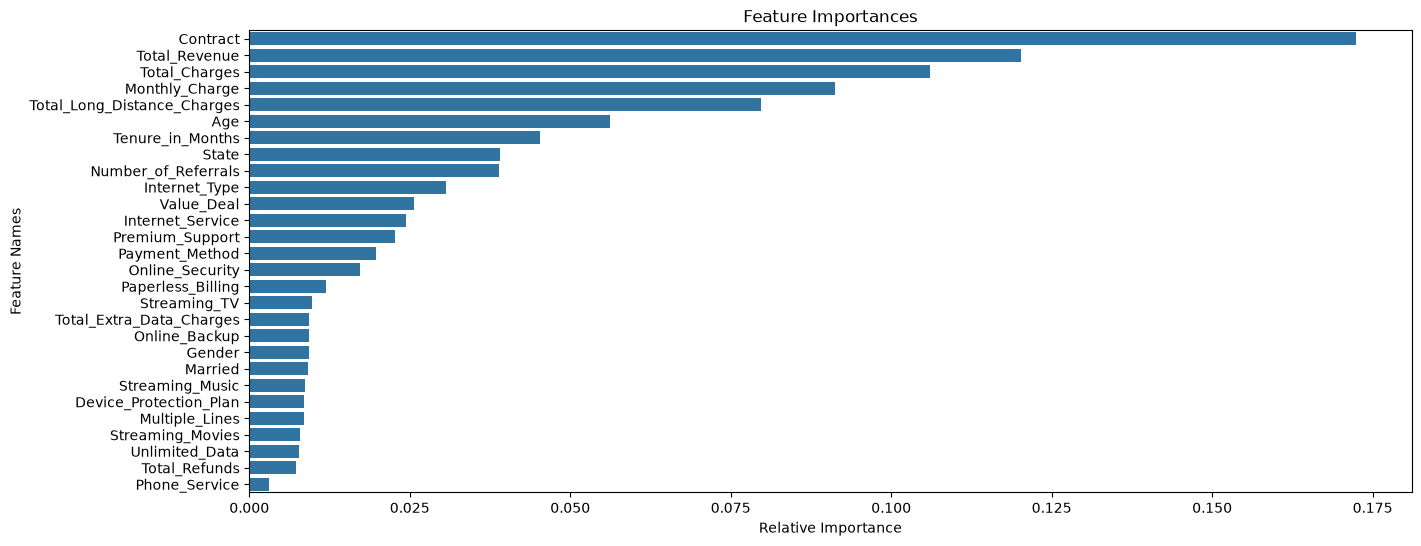

In [11]:
# Feature Selection using Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
 
# Plot the feature importances
plt.figure(figsize=(15, 6))
sns.barplot(x=importances[indices], y=X.columns[indices])
plt.title('Feature Importances')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Names')
plt.show()

In [12]:
# Define the path to the Joiner Data Excel file
file_path = r"C:\Users\Darshi\OneDrive\Documents\Telecom_churn_DA\Prediction_data.xlsx"

# Define the sheet name to read data from
sheet_name = 'vw_JoinData'
 
# Reading the data from the sheet into a DataFrame
new_data = pd.read_excel(file_path, sheet_name=sheet_name)
print(new_data.head())

# Retain the original DataFrame to preserve unencoded columns
original_data = new_data.copy()

# Retain the Customer_ID column
customer_ids = new_data['Customer_ID']

# Drop columns that won't be used for prediction in the encoded DataFrame
new_data = new_data.drop(['Customer_ID', 'Customer_Status', 'Churn_Category', 'Churn_Reason'], axis=1)
 
# Encode categorical variables using the saved label encoders
for column in new_data.select_dtypes(include=['object']).columns:
    new_data[column] = label_encoders[column].transform(new_data[column])

# Make predictions
new_predictions = rf_model.predict(new_data)
original_data['Customer_Status_Predicted'] = new_predictions
original_data = original_data[original_data['Customer_Status_Predicted'] == 1]
original_data.to_csv(r"C:\Users\Darshi\OneDrive\Documents\Telecom_churn_DA\Predictions.csv", index=False)
print("Rows saved:", len(original_data))

  Customer_ID  Gender  Age Married        State  Number_of_Referrals  \
0   11751-TAM  Female   18      No   Tamil Nadu                    5   
1   12056-WES    Male   27      No  West Bengal                    2   
2   12136-RAJ  Female   25     Yes    Rajasthan                    2   
3   12257-ASS  Female   39      No        Assam                    9   
4   12340-DEL  Female   51     Yes        Delhi                    0   

   Tenure_in_Months Value_Deal Phone_Service Multiple_Lines  ...  \
0                 7     Deal 5            No             No  ...   
1                20        NaN           Yes             No  ...   
2                35        NaN           Yes             No  ...   
3                 1        NaN           Yes             No  ...   
4                10        NaN           Yes             No  ...   

    Payment_Method Monthly_Charge Total_Charges Total_Refunds  \
0     Mailed Check      24.299999     38.450001           0.0   
1  Bank Withdrawal      90.4

C:\Users\Darshi\AppData\Local\Temp\ipykernel_19128\4001128256.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in new_data.select_dtypes(include=['object']).columns:


Rows saved: 378
